In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import json
import sys
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import dask
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import rioxarray as rxr
import seaborn as sns
import xarray as xr
from dask.diagnostics import ProgressBar

sys.path.append("../..")

from src.utils.constants import (
    EXTENT_BC,
    EXTENT_BC_MRRO,
    REFERENCE_PERIOD,
    MID_CENTURY_PERIOD,
)
from src.utils.utils_xarray import sel_extent
from src.data_processing.load_data import ClimateModelData
from src.conversion_energy.hydropower import simple_hydropower_potential

sns.set_style("whitegrid", {"grid.color": ".93"})

In [4]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"
path_data_temporary = Path(paths["path_data_temporary"])

path_energy_ch = path_data_processed / "energy" / "ch"
path_energy_europe = path_data_processed / "energy" / "europe"

path_figs = Path(paths["path_figs"])

In [4]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 34}
extent_ch = {"lat_min": 45.8, "lat_max": 47.9, "lon_min": 5.9, "lon_max": 10.5}
extent_pop = {"lat_min": 29, "lat_max": 76, "lon_min": -11, "lon_max": 31}

In [6]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

In [7]:
path_data_routed = Path("/net/argon/landclim2/pseubert/out_rcm/hist/CNRM-26")
path_data_routed_zarr = list(path_data_routed.glob("*/Qrouted_historical_*_m3s.zarr"))

In [13]:
ds_routed = ClimateModelData(
    path_data_routed_zarr,
    chunks="auto",
    # extent={"lat_min": 75, "lat_max": 30, "lon_min": -30, "lon_max": 41},
    # extent={"lat_min": 47.9, "lat_max": 45.8, "lon_min": 5.9, "lon_max": 10.5},
    extent={
        "lat_min": EXTENT_BC["lat_max"],
        "lat_max": EXTENT_BC["lat_min"],
        "lon_min": EXTENT_BC["lon_min"],
        "lon_max": EXTENT_BC["lon_max"],
    },
    check_calendar=False,
)

In [10]:
output_path_hydropower = (
    path_data_processed / "energy"
    / "europe"
    / "hydropower"
    / f"{climate_model_chain}_{climate_scenario}"
)
ds_hydropower = xr.open_zarr(output_path_hydropower / f"hydropower_{climate_model_chain}_{climate_scenario}.zarr", chunks="auto")

In [19]:
ds_hydropower = ds_hydropower.convert_calendar('standard', align_on='year')

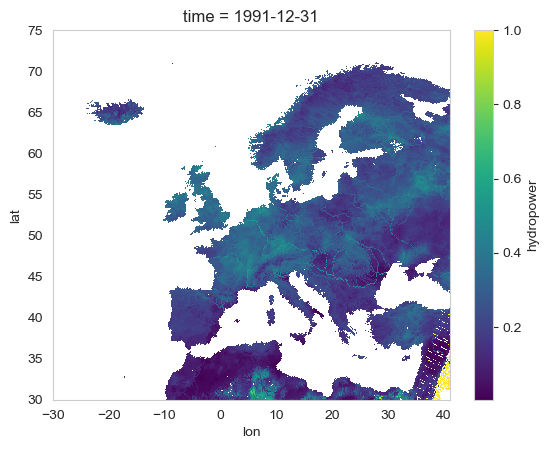

In [25]:
ds_hydropower.sel(time="1991").resample(time="YE").mean(dim="time").isel(time=0).hydropower.plot()

In [9]:
ds_routed.ds_data = ds_routed.ds_data.load()

In [ ]:
ds_hydropower = simple_hydropower_potential(
    ds_routed.ds_data,
    reference_period=REFERENCE_PERIOD,
    quantile_max=0.95,
    quantile_min=0.05,
).compute()

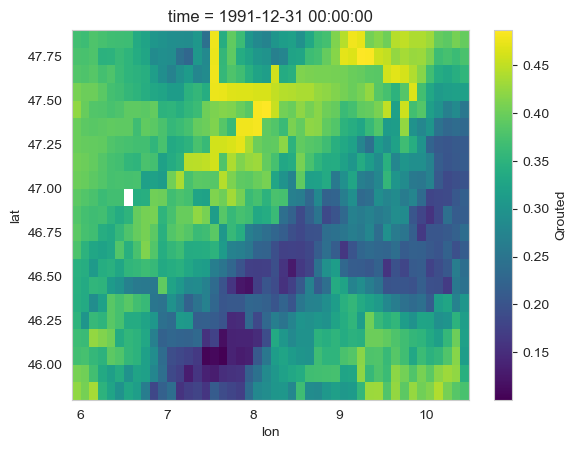

In [13]:
ds_hydropower.Qrouted.resample(time="YE").mean("time").isel(time=0).plot()

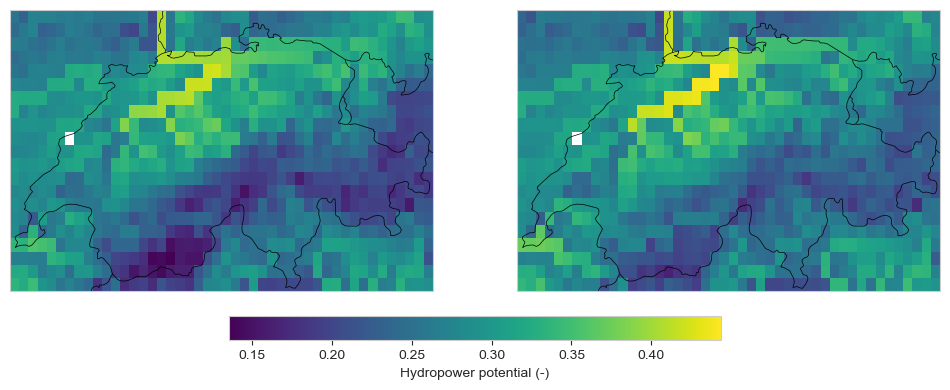

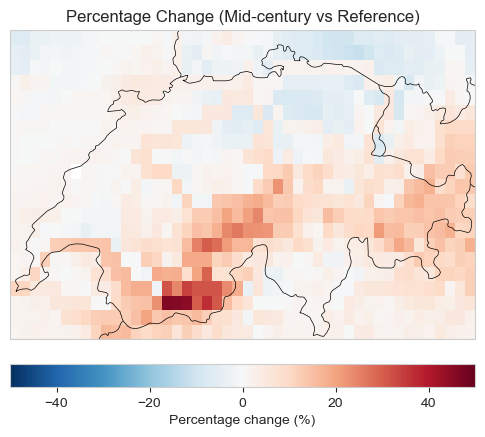

In [ ]:
fig, axs = plt.subplots(
    1, 2, figsize=(12, 8), subplot_kw={"projection": ccrs.Mercator()}
)

# Use the same colorbar for both subplots
ds_hydropower_mean_ref = ds_hydropower.Qrouted.sel(time=slice(*REFERENCE_PERIOD)).mean(
    "time"
)
ds_hydropower_mean_mid_century = ds_hydropower.Qrouted.sel(
    time=slice(*MID_CENTURY_PERIOD)
).mean("time")
vmin = min(
    [ds_hydropower_mean_ref.min().item(), ds_hydropower_mean_mid_century.min().item()]
)
vmax = max(
    [ds_hydropower_mean_ref.max().item(), ds_hydropower_mean_mid_century.max().item()]
)
ds_hydropower_mean_ref.plot(
    ax=axs[0],
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False,
    transform=ccrs.PlateCarree(),
)
ds_hydropower_mean_mid_century.plot(
    ax=axs[1],
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False,
    transform=ccrs.PlateCarree(),
)
for ax in axs:
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, edgecolor="black", linewidth=0.5)

cbar = fig.colorbar(
    axs[0].collections[0],
    ax=axs,
    orientation="horizontal",
    fraction=0.04,
    pad=0.04,
    label="Hydropower potential (-)",
)

# Calculate percentage change
percent_change = (
    100
    * (ds_hydropower_mean_mid_century - ds_hydropower_mean_ref)
    / ds_hydropower_mean_ref
)

# Add new subplot for percentage change
fig2, ax2 = plt.subplots(
    1, 1, figsize=(6, 8), subplot_kw={"projection": ccrs.Mercator()}
)
pcm = percent_change.plot(
    ax=ax2,
    cmap="RdBu_r",
    vmin=-50,
    vmax=50,
    add_colorbar=False,
    transform=ccrs.PlateCarree(),
)
ax2.coastlines()
ax2.add_feature(cfeature.BORDERS, edgecolor="black", linewidth=0.5)
cbar2 = fig2.colorbar(
    pcm,
    ax=ax2,
    orientation="horizontal",
    fraction=0.04,
    pad=0.04,
    label="Percentage change (%)",
)
ax2.set_title("Percentage Change (Mid-century vs Reference)")
plt.show()

In [40]:
path_data_routed = Path("/net/argon/landclim2/pseubert/out_rcm/hist/CNRM-85")
path_data_routed_zarr = list(path_data_routed.glob("*/Qrouted_historical_*_m3s.zarr"))

In [ ]:
ds_routed_rcp85 = ClimateModelData(
    path_data_routed_zarr,
    chunks="auto",
    # extent={"lat_min": 75, "lat_max": 30, "lon_min": -30, "lon_max": 41},
    extent={"lat_min": 47.9, "lat_max": 45.8, "lon_min": 5.9, "lon_max": 10.5},
    check_calendar=False,
)

In [42]:
ds_routed_rcp85.ds_data = ds_routed_rcp85.ds_data.load()

In [ ]:
ds_hydropower_rcp85 = simple_hydropower_potential(
    ds_routed_rcp85.ds_data,
    reference_period=REFERENCE_PERIOD,
    quantile_max=0.95,
    quantile_min=0.05,
).compute()

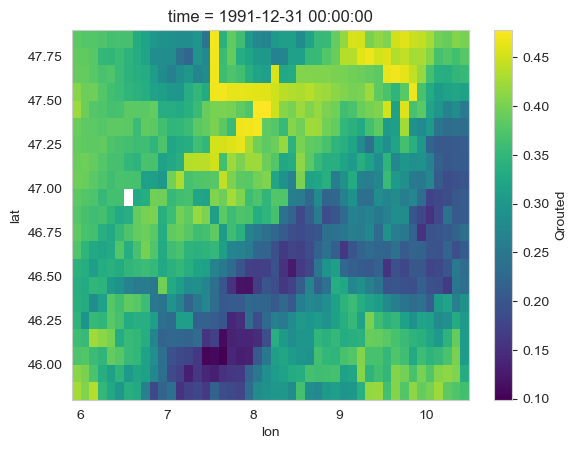

In [44]:
ds_hydropower_rcp85.Qrouted.resample(time="YE").mean("time").isel(time=0).plot()

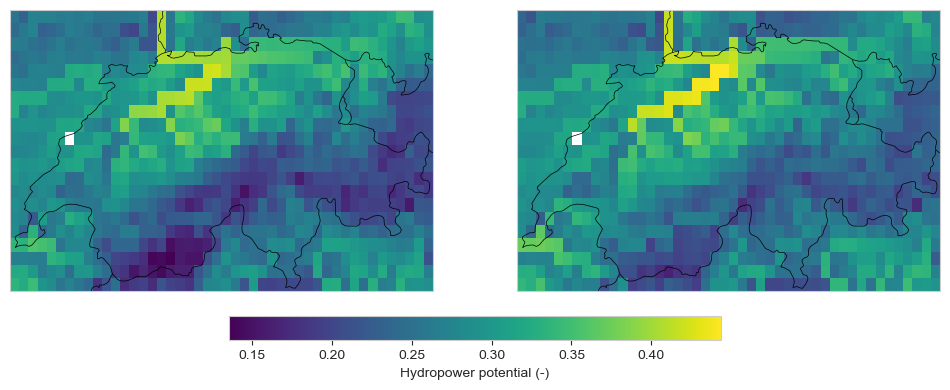

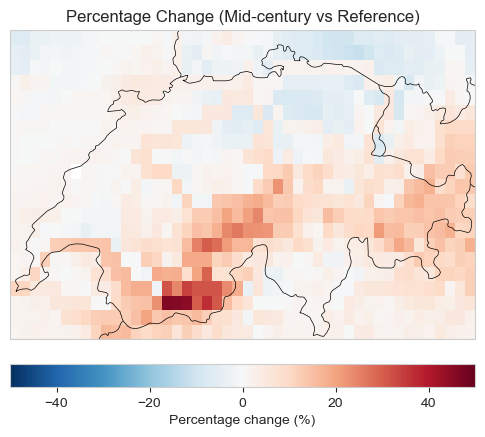

In [ ]:
fig, axs = plt.subplots(
    1, 2, figsize=(12, 8), subplot_kw={"projection": ccrs.Mercator()}
)

# Use the same colorbar for both subplots
ds_hydropower_rcp85_mean_ref = ds_hydropower_rcp85.Qrouted.sel(
    time=slice(*REFERENCE_PERIOD)
).mean("time")
ds_hydropower_rcp85_mean_mid_century = ds_hydropower_rcp85.Qrouted.sel(
    time=slice(*MID_CENTURY_PERIOD)
).mean("time")
vmin = min(
    [
        ds_hydropower_rcp85_mean_ref.min().item(),
        ds_hydropower_rcp85_mean_mid_century.min().item(),
    ]
)
vmax = max(
    [
        ds_hydropower_rcp85_mean_ref.max().item(),
        ds_hydropower_rcp85_mean_mid_century.max().item(),
    ]
)
ds_hydropower_rcp85_mean_ref.plot(
    ax=axs[0],
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False,
    transform=ccrs.PlateCarree(),
)
ds_hydropower_rcp85_mean_mid_century.plot(
    ax=axs[1],
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False,
    transform=ccrs.PlateCarree(),
)
for ax in axs:
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, edgecolor="black", linewidth=0.5)

cbar = fig.colorbar(
    axs[0].collections[0],
    ax=axs,
    orientation="horizontal",
    fraction=0.04,
    pad=0.04,
    label="Hydropower potential (-)",
)

# Calculate percentage change
percent_change_rcp85 = (
    100
    * (ds_hydropower_rcp85_mean_mid_century - ds_hydropower_rcp85_mean_ref)
    / ds_hydropower_rcp85_mean_ref
)

# Add new subplot for percentage change
fig2, ax2 = plt.subplots(
    1, 1, figsize=(6, 8), subplot_kw={"projection": ccrs.Mercator()}
)
pcm = percent_change_rcp85.plot(
    ax=ax2,
    cmap="RdBu_r",
    vmin=-50,
    vmax=50,
    add_colorbar=False,
    transform=ccrs.PlateCarree(),
)
ax2.coastlines()
ax2.add_feature(cfeature.BORDERS, edgecolor="black", linewidth=0.5)
cbar2 = fig2.colorbar(
    pcm,
    ax=ax2,
    orientation="horizontal",
    fraction=0.04,
    pad=0.04,
    label="Percentage change (%)",
)
ax2.set_title("Percentage Change (Mid-century vs Reference)")
plt.show()